**03 - Feature Selection and Ablation** (code-only copy). Explanations: [`docs/notebooks/03_feature_selection.md`](../../docs/notebooks/03_feature_selection.md)

## Setup: imports, paths and data loading

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
ROOT = Path.cwd().resolve()
while not (ROOT / 'CLAUDE.md').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.features import preprocessing as P
from src.features.feature_sets import FEATURE_SETS, GROUPS, group_variant, REDUCED_DROP, DOMAIN_DROP
from src.evaluation import feature_selection as F
from src.evaluation import run_feature_selection as R
from src.models.candidates import MODELS

pd.set_option('display.width', 220, 'display.max_columns', 40, 'display.max_rows', 120, 'display.max_colwidth', 90)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
df, X, y, folds = R.load()
print(len(df), 'rows |', len(folds), 'outer folds (5-fold x 3 repeats, stratified by price band, seed 42)')

1460 rows | 15 outer folds (5-fold x 3 repeats, stratified by price band, seed 42)


## 1. Existing Preprocessing Audit

In [2]:
rows = []
for name, fs in FEATURE_SETS.items():
    Z = fs.build().fit(X.iloc[folds[0][0]]).transform(X.iloc[folds[0][0]])
    rows.append(dict(feature_set=name, output_columns=Z.shape[1], pruned_input_columns=len(fs.drop_columns),
                     garage_age=fs.garage_age, description=fs.description))
display(pd.DataFrame(rows).set_index('feature_set'))

,output_columns,pruned_input_columns,garage_age,description
feature_set,,,,
full,190,0,True,all eligible predictors; nothing pruned; GarageAge added
reduced,166,20,False,project default: near-constant and redundant columns pruned
domain_informed,174,12,False,distinct economic components kept; exact composites pruned


## 3. Correlated Feature-Group Definitions

In [3]:
rows = []
for g, spec in GROUPS.items():
    for v in spec['variants']:
        fs = group_variant(g, v)
        kept = [c for c in spec['columns'] if c not in fs.drop_columns]
        if g == 'C_age':
            kept = f"year_features={fs.year_features}, garage_age={fs.garage_age}" + (", RemodAge dropped" if 'RemodAge' in fs.drop_columns else '')
        rows.append(dict(group=g, variant=v, kept=kept if isinstance(kept, str) else ', '.join(kept) or '(none)'))
display(pd.DataFrame(rows).set_index(['group', 'variant']))

kept
group        variant                                                                                        
A_garage     GarageCars only (reference)                                                          GarageCars
             GarageArea only                                                                      GarageArea
             both                                                                     GarageCars, GarageArea
             neither                                                                                  (none)
B_living     GrLivArea only (reference)                                                            GrLivArea
             TotRmsAbvGrd only                                                                  TotRmsAbvGrd
             both                                                                    GrLivArea, TotRmsAbvGrd
             neither                                                                                  (none)
C_age        engineered age (reference)                                  year_features=age, garage_age=False
             raw years                                                   year_features=raw, garage_age=False
             engineered age + GarageAge                                   year_features=age, garage_age=True
             engineered age, no RemodAge               year_features=age, garage_age=False, RemodAge dropped
D_floor_area TotalBsmtSF only (reference)                                                        TotalBsmtSF
             1stFlrSF only                                                                          1stFlrSF
             both                                                                      TotalBsmtSF, 1stFlrSF
             neither                                                                                  (none)
             TotalSF only                                                                            TotalSF
E_basement   total only (reference)                                                              TotalBsmtSF
             components only                                               BsmtFinSF1, BsmtFinSF2, BsmtUnfSF
             total + finished parts                                      TotalBsmtSF, BsmtFinSF1, BsmtFinSF2
             total + all parts (exact sum)                    TotalBsmtSF, BsmtFinSF1, BsmtFinSF2, BsmtUnfSF
F_bathrooms  TotalBathrooms only (reference)                                                  TotalBathrooms
             four components only                             FullBath, HalfBath, BsmtFullBath, BsmtHalfBath
             total + components (exact sum)   TotalBathrooms, FullBath, HalfBath, BsmtFullBath, BsmtHalfBath
             above-grade baths only                                                       FullBath, HalfBath
             none                                                                                     (none)

## 5. Training-Only Screening Diagnostics

In [4]:
vif, mi = R.screening_diagnostics(fold=0)
display(vif.set_index('feature_set').round(2))
cl = pd.read_csv(ROOT / 'reports/tables/correlation_clusters.csv')
display(cl[cl.feature.isin(['GrLivArea','TotRmsAbvGrd','GarageCars','GarageArea','TotalBsmtSF','1stFlrSF'])].round(3).set_index('feature'))
focus = ['OverallQual','GrLivArea','GarageCars','GarageArea','TotalBsmtSF','1stFlrSF','2ndFlrSF','TotalSF','TotRmsAbvGrd','TotalBathrooms','FullBath','HouseAge','RemodAge','BsmtFinSF1','BsmtUnfSF','GarageAge']
display(mi.loc[[f for f in focus if f in mi.index]].round(3).rename(columns=lambda c: 'MI nats, ' + c))

,n_output_cols,n_numeric,numeric_rank,n_inf_vif,n_vif_gt10_finite,max_finite_vif
feature_set,,,,,,
full,190,35,35,0,9,18382.91
reduced,166,18,18,0,0,4.20
domain_informed,174,26,26,0,0,7.13


,cluster,abs_spearman_price,suggest_keep
feature,,,
GrLivArea,13,0.731,True
TotRmsAbvGrd,13,0.533,False
GarageCars,16,0.691,True
GarageArea,16,0.649,False
TotalBsmtSF,22,0.603,True
1stFlrSF,22,0.575,False


,"MI nats, full","MI nats, reduced","MI nats, domain_informed"
OverallQual,0.582,0.582,0.581
GrLivArea,0.495,0.498,0.496
GarageCars,0.384,0.382,0.379
GarageArea,0.365,NaN,0.364
TotalBsmtSF,0.337,0.337,0.336
1stFlrSF,0.337,NaN,NaN
2ndFlrSF,0.218,NaN,0.224
TotalSF,0.699,NaN,NaN
TotRmsAbvGrd,0.198,NaN,0.197
TotalBathrooms,0.342,0.345,NaN


## 6. Feature Ablation Methodology

In [5]:
AB = pd.read_csv(R.OUT / 'ablation_folds.csv')
def ablation_table(group, model):
    spec = GROUPS[group]
    mets = {v: AB[(AB.model == model) & (AB.group == group) & (AB.variant == v)].sort_values('fold').reset_index(drop=True) for v in spec['variants']}
    return F.paired_vs_reference(mets, spec['reference'])
COLS = ['n_features', 'rmse_log', 'rmse_sd', 'mae_usd', 'mape_pct', 'diff', 'ci_lo', 'ci_hi', 'folds_better', 'verdict']
chk = AB.groupby(['model', 'group', 'variant']).fold.apply(lambda s: tuple(sorted(s)))
print('every ablation cell has the same 15 fold ids:', chk.nunique() == 1)

every ablation cell has the same 15 fold ids: True


## 7. Linear-Model Experiments (Ridge, alpha 10)

In [6]:
for g in GROUPS:
    print('\n' + g)
    display(ablation_table(g, 'ridge')[COLS].round({'rmse_log': 4, 'rmse_sd': 4, 'mae_usd': 0, 'mape_pct': 2, 'diff': 4, 'ci_lo': 4, 'ci_hi': 4, 'n_features': 1}))


A_garage


,n_features,rmse_log,rmse_sd,mae_usd,mape_pct,diff,ci_lo,ci_hi,folds_better,verdict
variant,,,,,,,,,,
GarageCars only (reference),166.9,0.1309,0.0212,15910.0,8.96,0.0000,0.0000,0.0000,0,reference
GarageArea only,166.9,0.1323,0.0233,16066.0,9.02,0.0013,-0.0016,0.0043,6,tie
both,167.9,0.1316,0.0222,15989.0,9.00,0.0007,-0.0009,0.0023,4,tie
neither,165.9,0.1329,0.0223,16257.0,9.12,0.0020,0.0001,0.0038,2,worse



B_living


,n_features,rmse_log,rmse_sd,mae_usd,mape_pct,diff,ci_lo,ci_hi,folds_better,verdict
variant,,,,,,,,,,
GrLivArea only (reference),166.9,0.1309,0.0212,15910.0,8.96,0.0000,0.0000,0.0000,0,reference
TotRmsAbvGrd only,166.9,0.1429,0.0230,17910.0,10.12,0.0119,0.0071,0.0168,0,worse
both,167.9,0.1310,0.0214,15920.0,8.97,0.0000,-0.0005,0.0006,8,tie
neither,165.9,0.1468,0.0224,18556.0,10.46,0.0159,0.0108,0.0210,0,worse



C_age


...

,n_features,rmse_log,rmse_sd,mae_usd,mape_pct,diff,ci_lo,ci_hi,folds_better,verdict
variant,,,,,,,,,,
TotalBsmtSF only (reference),166.9,0.1309,0.0212,15910.0,8.96,0.0000,0.0000,0.0000,0,reference
1stFlrSF only,166.9,0.1288,0.0179,15719.0,8.83,-0.0021,-0.0076,0.0033,11,tie
both,167.9,0.1306,0.0209,15841.0,8.92,-0.0003,-0.0012,0.0006,11,tie
neither,165.9,0.1284,0.0172,15756.0,8.84,-0.0025,-0.0090,0.0039,8,tie
TotalSF only,166.9,0.1301,0.0228,15766.0,8.89,-0.0008,-0.0060,0.0043,13,tie



E_basement


,n_features,rmse_log,rmse_sd,mae_usd,mape_pct,diff,ci_lo,ci_hi,folds_better,verdict
variant,,,,,,,,,,
total only (reference),166.9,0.1309,0.0212,15910.0,8.96,0.0000,0.0000,0.0000,0,reference
components only,168.9,0.1288,0.0191,15689.0,8.83,-0.0022,-0.0066,0.0023,11,tie
total + finished parts,168.9,0.1310,0.0228,15844.0,8.94,0.0001,-0.0026,0.0028,12,tie
total + all parts (exact sum),169.9,0.1313,0.0230,15858.0,8.95,0.0004,-0.0025,0.0032,7,tie



F_bathrooms


,n_features,rmse_log,rmse_sd,mae_usd,mape_pct,diff,ci_lo,ci_hi,folds_better,verdict
variant,,,,,,,,,,
TotalBathrooms only (reference),166.9,0.1309,0.0212,15910.0,8.96,0.0000,0.0000,0.0000,0,reference
four components only,169.9,0.1311,0.0214,15950.0,8.98,0.0002,-0.0002,0.0006,5,tie
total + components (exact sum),170.9,0.1312,0.0213,15947.0,8.98,0.0003,-0.0001,0.0006,3,tie
above-grade baths only,167.9,0.1319,0.0212,16161.0,9.07,0.0010,-0.0003,0.0023,3,tie
none,165.9,0.1322,0.0215,16213.0,9.09,0.0013,0.0001,0.0026,2,worse


## 8. Gradient Boosting Experiments

In [7]:
for g in GROUPS:
    print('\n' + g)
    display(ablation_table(g, 'gbr')[COLS].round({'rmse_log': 4, 'rmse_sd': 4, 'mae_usd': 0, 'mape_pct': 2, 'diff': 4, 'ci_lo': 4, 'ci_hi': 4, 'n_features': 1}))


A_garage


,n_features,rmse_log,rmse_sd,mae_usd,mape_pct,diff,ci_lo,ci_hi,folds_better,verdict
variant,,,,,,,,,,
GarageCars only (reference),166.9,0.1262,0.0124,15565.0,8.76,0.0000,0.0000,0.0000,0,reference
GarageArea only,166.9,0.1277,0.0136,15746.0,8.82,0.0015,-0.0006,0.0036,2,tie
both,167.9,0.1268,0.0136,15650.0,8.78,0.0006,-0.0015,0.0028,3,tie
neither,165.9,0.1284,0.0131,16020.0,9.01,0.0022,0.0006,0.0039,0,worse



B_living


,n_features,rmse_log,rmse_sd,mae_usd,mape_pct,diff,ci_lo,ci_hi,folds_better,verdict
variant,,,,,,,,,,
GrLivArea only (reference),166.9,0.1262,0.0124,15565.0,8.76,0.0000,0.0000,0.0000,0,reference
TotRmsAbvGrd only,166.9,0.1329,0.0123,16722.0,9.40,0.0067,0.0038,0.0097,0,worse
both,167.9,0.1263,0.0124,15574.0,8.76,0.0001,-0.0010,0.0013,5,tie
neither,165.9,0.1348,0.0116,17082.0,9.60,0.0086,0.0048,0.0125,0,worse



C_age


...

,n_features,rmse_log,rmse_sd,mae_usd,mape_pct,diff,ci_lo,ci_hi,folds_better,verdict
variant,,,,,,,,,,
TotalBsmtSF only (reference),166.9,0.1262,0.0124,15565.0,8.76,0.0000,0.0000,0.0000,0,reference
1stFlrSF only,166.9,0.1265,0.0124,15571.0,8.81,0.0003,-0.0032,0.0037,8,tie
both,167.9,0.1260,0.0126,15462.0,8.75,-0.0001,-0.0027,0.0024,8,tie
neither,165.9,0.1274,0.0126,15977.0,8.98,0.0013,-0.0012,0.0037,3,tie
TotalSF only,166.9,0.1266,0.0140,15310.0,8.68,0.0005,-0.0040,0.0049,7,tie



E_basement


,n_features,rmse_log,rmse_sd,mae_usd,mape_pct,diff,ci_lo,ci_hi,folds_better,verdict
variant,,,,,,,,,,
total only (reference),166.9,0.1262,0.0124,15565.0,8.76,0.0000,0.0000,0.0000,0,reference
components only,168.9,0.1267,0.0119,15641.0,8.85,0.0005,-0.0021,0.0031,5,tie
total + finished parts,168.9,0.1257,0.0130,15418.0,8.71,-0.0004,-0.0023,0.0015,9,tie
total + all parts (exact sum),169.9,0.1263,0.0126,15483.0,8.74,0.0001,-0.0018,0.0020,9,tie



F_bathrooms


,n_features,rmse_log,rmse_sd,mae_usd,mape_pct,diff,ci_lo,ci_hi,folds_better,verdict
variant,,,,,,,,,,
TotalBathrooms only (reference),166.9,0.1262,0.0124,15565.0,8.76,0.0000,0.0000,0.0000,0,reference
four components only,169.9,0.1263,0.0125,15606.0,8.78,0.0001,-0.0018,0.0020,5,tie
total + components (exact sum),170.9,0.1266,0.0124,15616.0,8.78,0.0004,-0.0008,0.0016,6,tie
above-grade baths only,167.9,0.1267,0.0126,15756.0,8.85,0.0005,-0.0025,0.0035,8,tie
none,165.9,0.1271,0.0128,15811.0,8.86,0.0010,-0.0013,0.0032,5,tie


### 8.2 Chart: feature-group ablation (Ridge and Gradient Boosting)

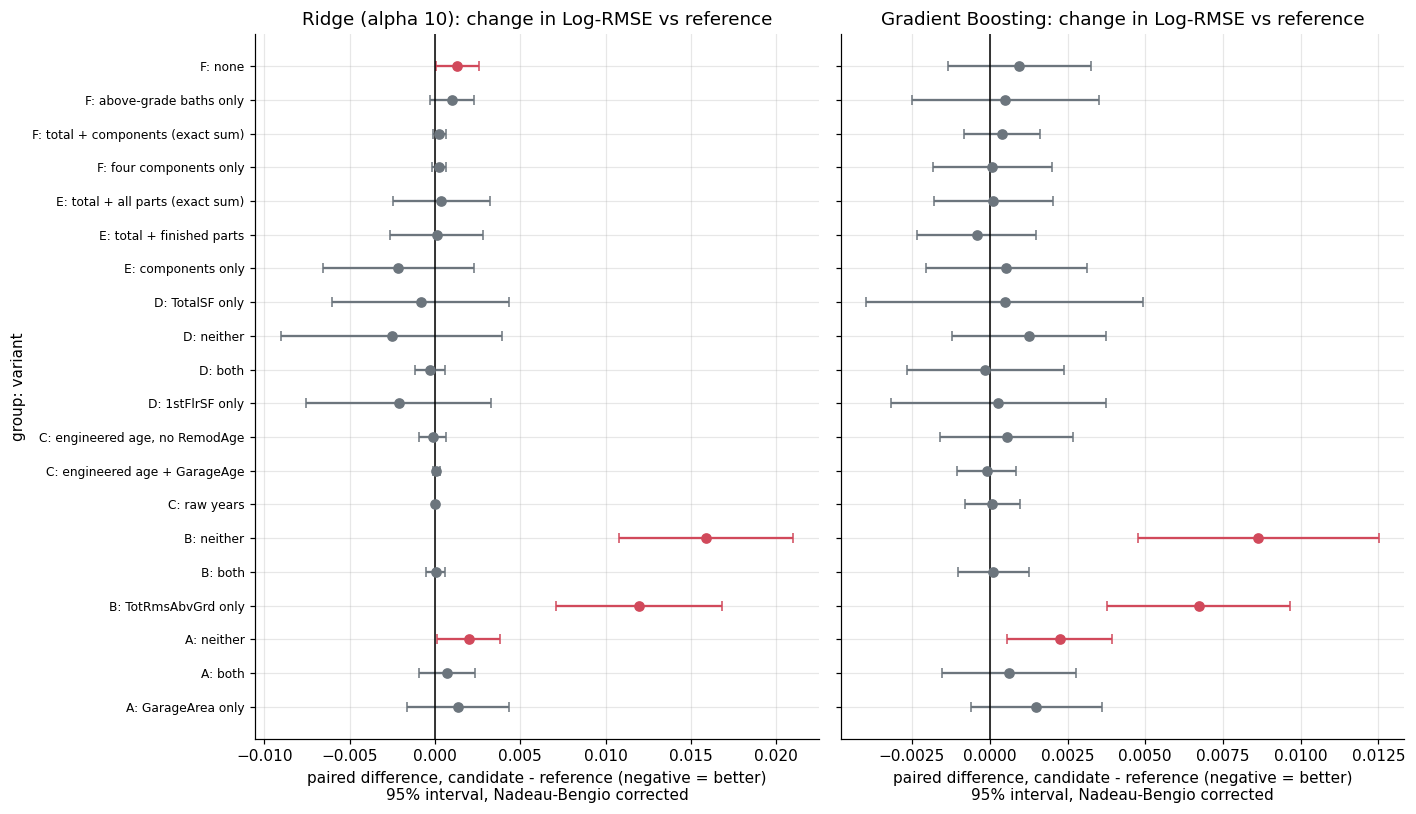

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 7.5), sharey=True)
colors = {'better': '#2a9d8f', 'worse': '#d1495b', 'tie': '#6c757d', 'reference': '#000000'}
for ax, model, title in zip(axes, ['ridge', 'gbr'], ['Ridge (alpha 10)', 'Gradient Boosting']):
    labels, k = [], 0
    for g in GROUPS:
        t = ablation_table(g, model)
        for v, r in t.iterrows():
            if r.verdict == 'reference':
                continue
            ax.errorbar(r['diff'], k, xerr=[[r['diff'] - r.ci_lo], [r.ci_hi - r['diff']]], fmt='o', color=colors[r.verdict], capsize=3)
            labels.append(f'{g[0]}: {v}'); k += 1
    ax.axvline(0, color='k', lw=1); ax.set_title(f'{title}: change in Log-RMSE vs reference'); ax.set_xlabel('paired difference, candidate - reference (negative = better)\n95% interval, Nadeau-Bengio corrected')
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8); ax.invert_yaxis()
axes[0].set_ylabel('group: variant')
plt.tight_layout(); plt.show()

### 8.3 Sensitivity (Ridge)

In [9]:
# Sensitivity (Ridge): is the floor-area / basement hint caused by the two known outliers (Ids 524, 1299) in the training rows?
ids = df.Id.values
folds_ex = [(tr[~np.isin(ids[tr], P.SUGGESTED_TRAINING_EXCLUSIONS)], va) for tr, va in folds]
rows = []
for g, vs in [('D_floor_area', ['TotalBsmtSF only (reference)', '1stFlrSF only', 'neither']), ('E_basement', ['total only (reference)', 'components only'])]:
    for lab, ff in [('all training rows', folds), ('training excludes 524, 1299', folds_ex)]:
        mets = {v: F.run_cv(F.make_pipeline(group_variant(g, v), 'ridge'), X, y, ff)[0] for v in vs}
        t = F.paired_vs_reference(mets, vs[0]); t['group'] = g; t['training'] = lab
        rows.append(t.reset_index())
display(pd.concat(rows).set_index(['group', 'training', 'variant'])[['rmse_log', 'diff', 'ci_lo', 'ci_hi', 'folds_better', 'verdict']].round(4))

rmse_log    diff   ci_lo   ci_hi  folds_better    verdict
group        training                    variant                                                                                
D_floor_area all training rows           TotalBsmtSF only (reference)    0.1309  0.0000  0.0000  0.0000             0  reference
                                         1stFlrSF only                   0.1288 -0.0021 -0.0076  0.0033            11        tie
                                         neither                         0.1284 -0.0025 -0.0090  0.0039             8        tie
             training excludes 524, 1299 TotalBsmtSF only (reference)    0.1293  0.0000  0.0000  0.0000             0  reference
                                         1stFlrSF only                   0.1267 -0.0025 -0.0101  0.0050             7        tie
                                         neither                         0.1262 -0.0030 -0.0119  0.0059             8        tie
E_basement   all training rows           total only (reference)          0.1309  0.0000  0.0000  0.0000             0  reference
                                         components only                 0.1288 -0.0022 -0.0066  0.0023            11        tie
             training excludes 524, 1299 total only (reference)          0.1293  0.0000  0.0000  0.0000             0  reference
                                         components only                 0.1272 -0.0021 -0.0077  0.0036             7        tie

## 9. Permutation Importance and Lasso Diagnostics

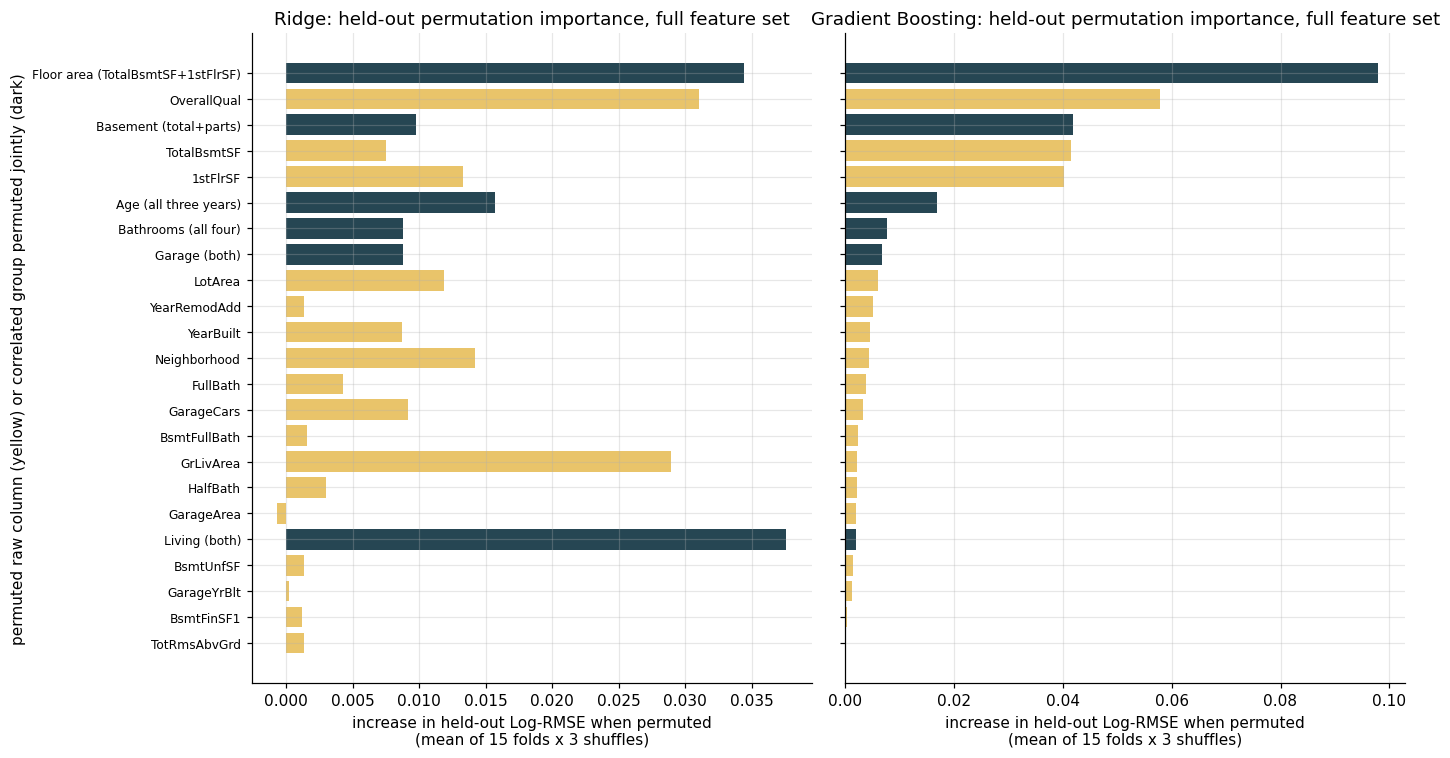

mean_delta  sd_delta  share_folds_positive
model group                                                                        
ridge GarageCars                             0.0092    0.0052                0.8667
      GarageArea                            -0.0007    0.0014                0.3333
      Garage (both)                          0.0088    0.0046                0.9333
      GrLivArea                              0.0289    0.0118                1.0000
      TotRmsAbvGrd                           0.0014    0.0015                0.8667
      Living (both)                          0.0376    0.0118                1.0000
      TotalBsmtSF                            0.0075    0.0066                0.9333
      1stFlrSF                               0.0133    0.0067                0.9333
      Floor area (TotalBsmtSF+1stFlrSF)      0.0344    0.0089                1.0000
gbr   GarageCars                             0.0033    0.0017                1.0000
      GarageArea                             0.0020    0.0024                0.8667
      Garage (both)                          0.0067    0.0033                0.9333
      GrLivArea                              0.0022    0.0024                0.9333
      TotRmsAbvGrd                           0.0000    0.0003                0.5333
      Living (both)                          0.0020    0.0023                0.9333
      TotalBsmtSF                            0.0416    0.0067                1.0000
      1stFlrSF                               0.0402    0.0055                1.0000
      Floor area (TotalBsmtSF+1stFlrSF)      0.0980    0.0095                1.0000

In [10]:
PI = pd.read_csv(R.OUT / 'permutation_importance.csv')
pt = PI.pivot(index='group', columns='model', values='mean_delta').sort_values('gbr')
fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
for ax, m, t in zip(axes, ['ridge', 'gbr'], ['Ridge', 'Gradient Boosting']):
    is_group = [('(' in g) or g.startswith('Age') for g in pt.index]
    ax.barh(range(len(pt)), pt[m], color=['#264653' if gg else '#e9c46a' for gg in is_group])
    ax.set_yticks(range(len(pt))); ax.set_yticklabels(pt.index, fontsize=8)
    ax.set_title(f'{t}: held-out permutation importance, full feature set'); ax.set_xlabel('increase in held-out Log-RMSE when permuted\n(mean of 15 folds x 3 shuffles)')
axes[0].set_ylabel('permuted raw column (yellow) or correlated group permuted jointly (dark)')
plt.tight_layout(); plt.show()
display(PI[PI.group.isin(['GrLivArea','TotRmsAbvGrd','Living (both)','GarageCars','GarageArea','Garage (both)','TotalBsmtSF','1stFlrSF','Floor area (TotalBsmtSF+1stFlrSF)'])].round(4).set_index(['model','group']))

### 9.2 Lasso stability across feature sets (non-zero share per feature)

feature_set,"non-zero share, domain_informed","non-zero share, full","non-zero share, reduced"
feature,,,
GarageCars,1.00,1.00,1.00
GarageArea,0.53,0.33,NaN
GrLivArea,1.00,1.00,1.00
TotRmsAbvGrd,0.93,0.93,NaN
TotalBsmtSF,0.87,0.93,0.93
1stFlrSF,NaN,0.80,NaN
2ndFlrSF,0.80,0.07,NaN
TotalSF,NaN,1.00,NaN
BsmtFinSF1,1.00,1.00,NaN


,output_columns,always_nonzero,never_nonzero,sometimes,mean_alpha
feature_set,,,,,
domain_informed,183,37,28,118,0.00060
full,199,37,52,110,0.00075
reduced,175,32,27,116,0.00061


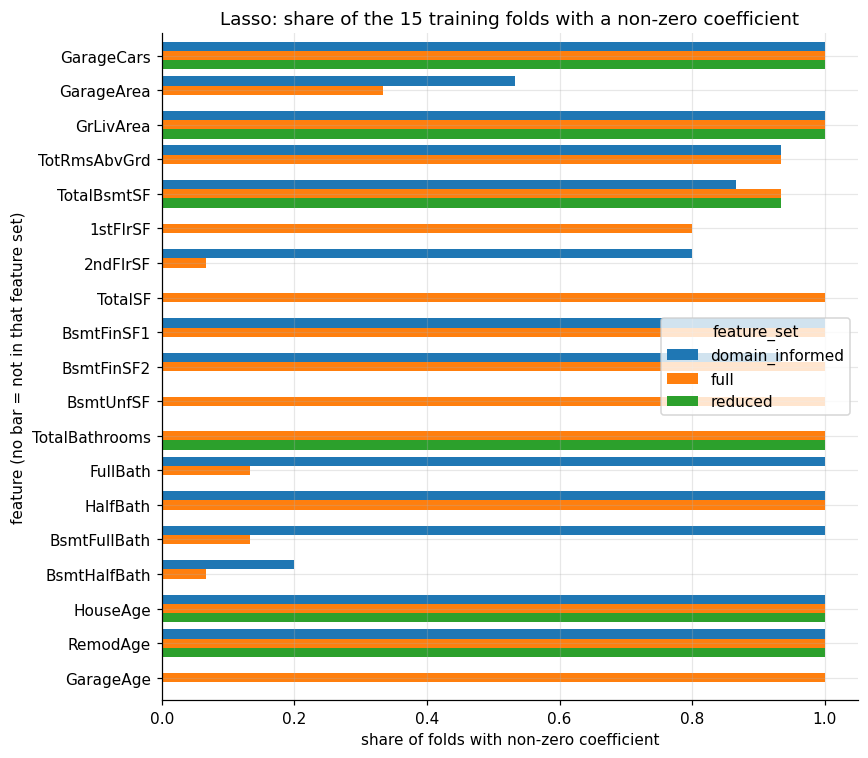

In [11]:
L = pd.read_csv(R.OUT / 'lasso_stability.csv')
focus = ['GarageCars','GarageArea','GrLivArea','TotRmsAbvGrd','TotalBsmtSF','1stFlrSF','2ndFlrSF','TotalSF','BsmtFinSF1','BsmtFinSF2','BsmtUnfSF','TotalBathrooms','FullBath','HalfBath','BsmtFullBath','BsmtHalfBath','HouseAge','RemodAge','GarageAge']
share = L[L.feature.isin(focus)].pivot(index='feature', columns='feature_set', values='nonzero_share').reindex(focus)
display(share.round(2).rename(columns=lambda c: 'non-zero share, ' + c))
summ = L.groupby('feature_set').agg(output_columns=('feature', 'size'), always_nonzero=('nonzero_share', lambda s: int((s == 1).sum())),
                                      never_nonzero=('nonzero_share', lambda s: int((s == 0).sum())), sometimes=('nonzero_share', lambda s: int(((s > 0) & (s < 1)).sum())),
                                      mean_alpha=('mean_alpha', 'first'))
display(summ.round(5))
ax = share.fillna(0).plot.barh(figsize=(8, 7), width=.8); ax.invert_yaxis()
ax.set_title('Lasso: share of the 15 training folds with a non-zero coefficient'); ax.set_xlabel('share of folds with non-zero coefficient'); ax.set_ylabel('feature (no bar = not in that feature set)')
plt.tight_layout(); plt.show()

## 10. Consolidated Feature-Set Comparison

In [12]:
CMP = pd.read_csv(R.OUT / 'comparison_folds.csv')
rows = []
for m in MODELS:
    mets = {s: CMP[(CMP.model == m) & (CMP.feature_set == s)].sort_values('fold').reset_index(drop=True) for s in FEATURE_SETS}
    t = F.paired_vs_reference(mets, 'reduced'); t.insert(0, 'model', m); rows.append(t.reset_index().rename(columns={'variant': 'feature_set'}))
CT = pd.concat(rows, ignore_index=True)
show = CT[['model', 'feature_set', 'n_features', 'rmse_log', 'rmse_sd', 'mae_usd', 'mape_pct', 'diff', 'ci_lo', 'ci_hi', 'folds_better', 'verdict']].rename(
    columns={'n_features': 'feature count', 'rmse_log': 'Log-RMSE', 'rmse_sd': 'CV variability (sd)', 'mae_usd': 'MAE USD', 'mape_pct': 'MAPE %'})
display(show.round({'feature count': 0, 'Log-RMSE': 4, 'CV variability (sd)': 4, 'MAE USD': 0, 'MAPE %': 2, 'diff': 4, 'ci_lo': 4, 'ci_hi': 4}).set_index(['model', 'feature_set']))

feature count  Log-RMSE  CV variability (sd)  MAE USD  MAPE %    diff   ci_lo   ci_hi  folds_better    verdict
model      feature_set                                                                                                                    
ols        full                     190.0    0.1448               0.0301  16912.0    9.55  0.0107 -0.0123  0.0337             2        tie
           reduced                  167.0    0.1341               0.0207  16362.0    9.22  0.0000  0.0000  0.0000             0  reference
           domain_informed          175.0    0.1355               0.0238  16455.0    9.32  0.0015 -0.0036  0.0065             6        tie
ridge      full                     190.0    0.1327               0.0264  15874.0    9.01  0.0018 -0.0064  0.0099             7        tie
           reduced                  167.0    0.1309               0.0210  15871.0    8.95  0.0000  0.0000  0.0000             0  reference
           domain_informed          175.0    0.1321               0.0241  15949.0    9.03  0.0012 -0.0033  0.0058             8        tie
lasso      full                     190.0    0.1294               0.0259  15652.0    8.82  0.0007 -0.0082  0.0096            12        tie
           reduced                  167.0    0.1288               0.0203  15813.0    8.87  0.0000  0.0000  0.0000             0  reference
           domain_informed          175.0    0.1299               0.0238  15846.0    8.91  0.0011 -0.0041  0.0064             8        tie
elasticnet full                     190.0    0.1295               0.0259  15637.0    8.83  0.0005 -0.0085  0.0095            12        tie
           reduced                  167.0    0.1290               0.0203  15833.0    8.88  0.0000  0.0000  0.0000             0  reference
           domain_informed          175.0    0.1300               0.0239  15842.0    8.92  0.0011 -0.0042  0.0064             9        tie
rf         full                     190.0    0.1375               0.0102  16592.0    9.43 -0.0000 -0.0028  0.0028             9        tie
           reduced                  167.0    0.1375               0.0102  16865.0    9.44  0.0000  0.0000  0.0000             0  reference
           domain_informed          175.0    0.1380               0.0109  16771.0    9.45  0.0005 -0.0015  0.0025             5        tie
gbr        full                     190.0    0.1273               0.0142  15256.0    8.67  0.0011 -0.0045  0.0067             6        tie
           reduced                  167.0    0.1262               0.0124  15565.0    8.76  0.0000  0.0000  0.0000             0  reference
           domain_informed          175.0    0.1270               0.0137  15648.0    8.81  0.0008 -0.0029  0.0045             5        tie

### 10.2 Chart: Log-RMSE by model and feature set

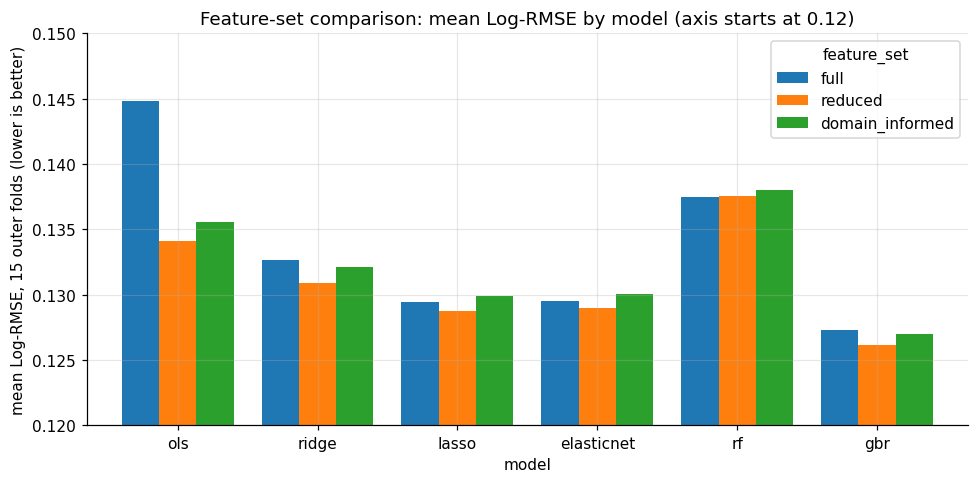

In [13]:
piv = CT.pivot(index='model', columns='feature_set', values='rmse_log').reindex(MODELS)[['full', 'reduced', 'domain_informed']]
ax = piv.plot.bar(figsize=(9, 4.5), width=.8, ylim=(.12, .15)); ax.set_ylabel('mean Log-RMSE, 15 outer folds (lower is better)'); ax.set_xlabel('model')
ax.set_title('Feature-set comparison: mean Log-RMSE by model (axis starts at 0.12)'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 11. Selection Stability and Uncertainty

In [14]:
N = pd.read_csv(R.OUT / 'nested_folds.csv')
nested = N.groupby('model').agg(rmse_log=('rmse_log', 'mean'), rmse_sd=('rmse_log', 'std'), mae_usd=('mae', 'mean'), mape_pct=('mape', 'mean'))
sel = N.groupby(['model', 'selected']).size().unstack(fill_value=0)
direct = CT[CT.feature_set == 'reduced'].set_index('model').loc[['ridge', 'gbr'], ['rmse_log']].rename(columns={'rmse_log': 'reduced, outer folds (no selection)'})
display(nested.join(sel.add_prefix('chosen in folds: ')).join(direct).round(4))

T = pd.read_csv(R.OUT / 'temporal.csv')
tp = T.pivot(index='model', columns='feature_set', values='rmse_log').reindex(MODELS)[['full', 'reduced', 'domain_informed']]
print('Temporal split Log-RMSE (train n=%d, test n=%d)' % (T.n_train[0], T.n_test[0])); display(tp.round(4))
print('Temporal split MAE (USD)'); display(T.pivot(index='model', columns='feature_set', values='mae').reindex(MODELS)[['full', 'reduced', 'domain_informed']].round(0))
cv_rank = CT.pivot(index='model', columns='feature_set', values='rmse_log').reindex(MODELS)[['full', 'reduced', 'domain_informed']].rank(axis=1)
print('rank of each set per model (1 = lowest Log-RMSE): repeated CV vs temporal')
display(pd.concat({'repeated CV': cv_rank, 'temporal': tp.rank(axis=1)}, axis=1))

,rmse_log,rmse_sd,mae_usd,mape_pct,chosen in folds: reduced,"reduced, outer folds (no selection)"
model,,,,,,
gbr,0.1262,0.0124,15565.3876,8.7599,15,0.1262
ridge,0.1309,0.0210,15870.5017,8.9519,15,0.1309


Temporal split Log-RMSE (train n=947, test n=513)


feature_set,full,reduced,domain_informed
model,,,
ols,0.1427,0.1374,0.1380
ridge,0.1341,0.1333,0.1328
lasso,0.1305,0.1313,0.1307
elasticnet,0.1308,0.1313,0.1307
rf,0.1511,0.1487,0.1500
gbr,0.1337,0.1321,0.1334


Temporal split MAE (USD)


feature_set,full,reduced,domain_informed
model,,,
ols,16814.0,16414.0,16433.0
ridge,15724.0,15892.0,15867.0
lasso,15530.0,15760.0,15763.0
elasticnet,15479.0,15761.0,15764.0
rf,17815.0,17514.0,17529.0
gbr,15532.0,15876.0,15849.0


rank of each set per model (1 = lowest Log-RMSE): repeated CV vs temporal


repeated CV                         temporal                        
feature_set        full reduced domain_informed     full reduced domain_informed
model                                                                           
ols                 3.0     1.0             2.0      3.0     1.0             2.0
ridge               3.0     1.0             2.0      3.0     2.0             1.0
lasso               2.0     1.0             3.0      1.0     3.0             2.0
elasticnet          2.0     1.0             3.0      2.0     3.0             1.0
rf                  1.0     2.0             3.0      3.0     1.0             2.0
gbr                 3.0     1.0             2.0      3.0     1.0             2.0

## 13. Leakage Verification

In [15]:
import unittest, io
suite = unittest.defaultTestLoader.loadTestsFromName('tests.test_feature_sets')
buf = io.StringIO(); res = unittest.TextTestRunner(stream=buf, verbosity=0).run(suite)
print(f'tests.test_feature_sets: ran {res.testsRun}, failures {len(res.failures)}, errors {len(res.errors)}')

checks = []
def add(name, ok, detail=''): checks.append((name, 'PASS' if ok else 'FAIL', detail))
tr, va = folds[0]
outs = {n: fs.build().fit(X.iloc[tr]).transform(X.iloc[va]) for n, fs in FEATURE_SETS.items()}
add('sale-context, identifiers and target never in any output', all(not any(c == b or c.startswith(b + '_') for b in ['SalePrice', 'Id'] + P.SALE_CONTEXT) for Z in outs.values() for c in Z.columns))
add('output complete and finite on unseen validation rows (all sets)', all(np.isfinite(Z.values).all() for Z in outs.values()))
add('no duplicated output columns', all(Z.columns.is_unique for Z in outs.values()))
add('same folds in every ablation and comparison cell', AB.groupby(['model', 'group', 'variant']).fold.apply(lambda s: tuple(sorted(s))).nunique() == 1
    and CMP.groupby(['model', 'feature_set']).fold.apply(lambda s: tuple(sorted(s))).nunique() == 1)
add('folds reproducible (get_folds is deterministic)', all((a[0] == b[0]).all() and (a[1] == b[1]).all() for a, b in zip(folds, R.load()[3])))
add('reference ablation cell equals the reduced set exactly', all(group_variant(g, s['reference']).drop_columns == FEATURE_SETS['reduced'].drop_columns for g, s in GROUPS.items()))
add('reduced set equals build_preprocessor defaults', list(outs['reduced'].columns) == list(P.build_preprocessor('baseline').fit(X.iloc[tr]).transform(X.iloc[va]).columns))
add('age features use a fixed reference year (2010), not the sale year', P.PropertyFeatureBuilder().reference_year == 2010 and not set(P.SALE_CONTEXT) & set(outs['full'].columns))
add('validation rows do not influence fitted preprocessing', res.wasSuccessful(), 'unit test test_preprocessing_statistics_come_from_training_rows_only')
add('selector scores candidates on training rows only', res.wasSuccessful(), 'FeatureSetSelector.fit receives outer training rows only (unit test)')
display(pd.DataFrame(checks, columns=['check', 'result', 'detail']).set_index('check'))

tests.test_feature_sets: ran 15, failures 0, errors 0


,result,detail
check,,
"sale-context, identifiers and target never in any output",PASS,
output complete and finite on unseen validation rows (all sets),PASS,
no duplicated output columns,PASS,
same folds in every ablation and comparison cell,PASS,
folds reproducible (get_folds is deterministic),PASS,
reference ablation cell equals the reduced set exactly,PASS,
reduced set equals build_preprocessor defaults,PASS,
"age features use a fixed reference year (2010), not the sale year",PASS,
validation rows do not influence fitted preprocessing,PASS,unit test test_preprocessing_statistics_come_from_training_rows_only
